# Assignment 4: Student Placement Classification

* Name: Yashraj Ghule
* Div: E
* Batch: E1
* Roll no: 316
* PRN: 202401040319

**GITHUB:** https://github.com/Yashraj221B/AIML_TH_LAB/tree/main/C.A/Practical-04-Student-Placement-Classification

## Problem Statement

Develop classification models (SVM, Decision Trees, KNN, and Naïve Bayes),evaluate performance using relevant metrics(accuracy, precision, recall, F1-score, loss)and summarize the findings of comparative analysis to discuss the suitability of each algorithm for various classification tasks.

**Dataset:** `student_placement_dataset.csv`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, log_loss,
                             roc_auc_score, roc_curve, classification_report, ConfusionMatrixDisplay)

# 1. Data Preprocessing

## Loading the Data

In [2]:
df = pd.read_csv("data/student_placement_dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (1200, 18)


,Student_ID,Gender,Branch,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular,Placed
0,STU1000,Male,Mechanical,85.2,75.9,7.17,2,0.0,3,1,65.0,Medium,1.8,Tier-3,Yes,7.98,No,No
1,STU1001,Male,IT,85.0,72.7,6.41,0,0.0,3,2,69.0,Low,2.5,Tier-3,No,12.46,Yes,Yes
2,STU1002,Female,Civil,79.7,85.1,7.46,1,1.0,2,0,72.0,Medium,7.3,Tier-3,Yes,5.70,No,Yes
3,STU1003,Female,Mechanical,81.6,67.0,4.51,1,1.0,0,3,63.0,Medium,20.3,Tier-2,Yes,3.68,No,No
4,STU1004,Male,Computer,70.5,78.8,8.19,0,0.0,2,0,62.0,High,3.5,Tier-1,No,18.97,Yes,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Student_ID             1200 non-null   str    
 1   Gender                 1200 non-null   str    
 2   Branch                 1200 non-null   str    
 3   SSC_Percentage         1200 non-null   float64
 4   HSC_Percentage         1171 non-null   float64
 5   CGPA                   1144 non-null   float64
 6   Active_Backlogs        1200 non-null   int64  
 7   Internships            1150 non-null   float64
 8   Projects               1200 non-null   int64  
 9   Certifications         1200 non-null   int64  
 10  Aptitude_Score         1119 non-null   float64
 11  Communication_Skill    1141 non-null   str    
 12  Coding_Hours_Per_Week  1100 non-null   float64
 13  City_Tier              1173 non-null   str    
 14  Hostel_Resident        1200 non-null   str    
 15  Family_Income_L

## Missing Values

In [4]:
missing = df.isnull().sum()
print(missing[missing > 0])
print()
print("Rows with at least one missing value:", df.isnull().any(axis=1).sum(), "out of", len(df))

HSC_Percentage            29
CGPA                      56
Internships               50
Aptitude_Score            81
Communication_Skill       59
Coding_Hours_Per_Week    100
City_Tier                 27
Family_Income_LPA        131
dtype: int64

Rows with at least one missing value: 444 out of 1200


8 columns have missing values and 444 of 1200 rows (37%) have at least one, so dropping rows would lose too much data. Filled with the median (numbers) and mode (categories).

## Exploring the Data

In [5]:
print(df["Placed"].value_counts())
print()
print(df.groupby("Placed")[["CGPA", "Aptitude_Score", "Active_Backlogs", "Internships", "Projects", "Coding_Hours_Per_Week"]].mean().round(2))

Placed
No     673
Yes    527
Name: count, dtype: int64

        CGPA  Aptitude_Score  Active_Backlogs  Internships  Projects  \
Placed                                                                 
No      6.15           56.82             1.58         0.88      2.02   
Yes     7.10           67.08             0.66         1.16      2.35   

        Coding_Hours_Per_Week  
Placed                         
No                       6.72  
Yes                      7.22  


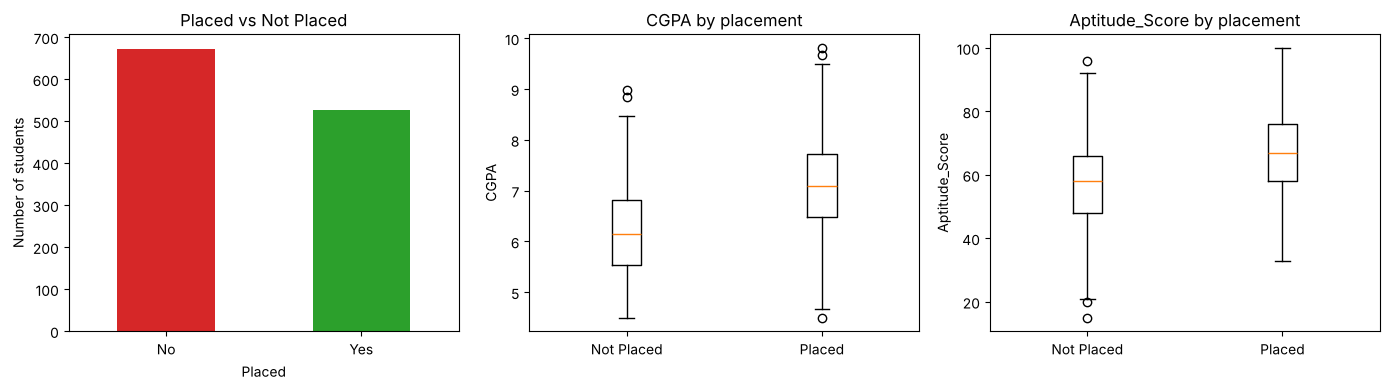

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))

df["Placed"].value_counts().plot(kind="bar", ax=ax[0], color=["tab:red", "tab:green"], rot=0)
ax[0].set_title("Placed vs Not Placed")
ax[0].set_ylabel("Number of students")

for a, col in zip(ax[1:], ["CGPA", "Aptitude_Score"]):
    a.boxplot([df.loc[df["Placed"] == "No", col].dropna(), df.loc[df["Placed"] == "Yes", col].dropna()])
    a.set_xticklabels(["Not Placed", "Placed"])
    a.set_title(col + " by placement")
    a.set_ylabel(col)

plt.tight_layout()
plt.show()

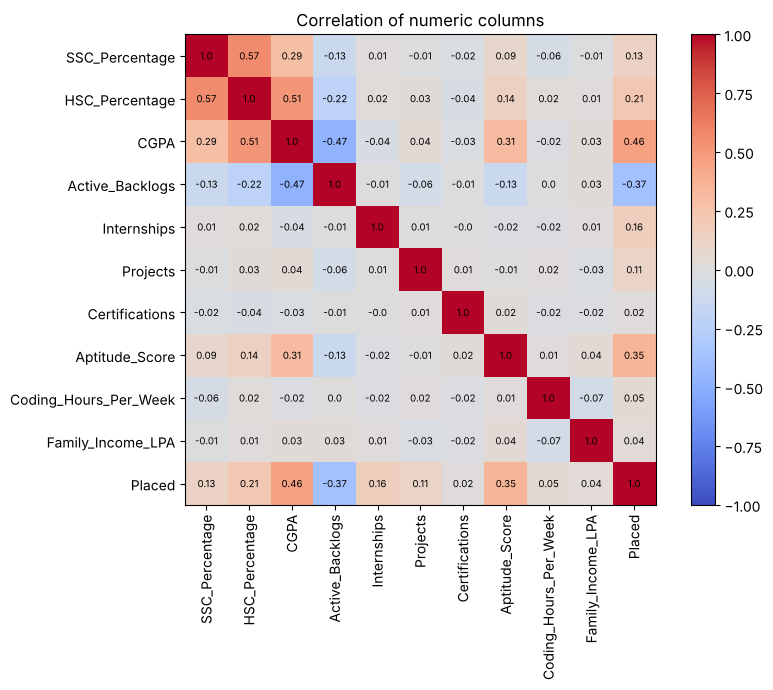

In [7]:
corr_data = df.drop(columns="Student_ID").copy()
corr_data["Placed"] = (corr_data["Placed"] == "Yes").astype(int)
corr = corr_data.corr(numeric_only=True)

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha="center", va="center", fontsize=7)
plt.title("Correlation of numeric columns")
plt.tight_layout()
plt.show()

43.9% of the students are placed, so the classes are slightly unbalanced. Placed students have higher CGPA (7.10 vs 6.15), higher aptitude score (67.1 vs 56.8) and fewer backlogs (0.66 vs 1.58). CGPA (0.46), Active_Backlogs (-0.37) and Aptitude_Score (0.35) correlate most with Placed. Certifications, Coding_Hours_Per_Week and Family_Income_LPA are close to 0.

## Features, Target and Train-Test Split

In [8]:
# Student_ID is only an identifier, so it is dropped
X = df.drop(columns=["Student_ID", "Placed"])
y = (df["Placed"] == "Yes").astype(int)   # 1 = Placed, 0 = Not Placed

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Placed share in train:", round(y_train.mean(), 3), " in test:", round(y_test.mean(), 3))

Train: (960, 16)  Test: (240, 16)
Placed share in train: 0.44  in test: 0.438


80/20 split with stratify. The split is done before imputing and scaling, so the test data does not affect the medians, modes or scaler.

## Handling Missing Values

In [9]:
num_cols = X_train.select_dtypes("number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

# median for numbers, most frequent value for categories (taken from the training data only)
medians = X_train[num_cols].median()
modes = X_train[cat_cols].mode().iloc[0]

X_train = X_train.fillna(medians).fillna(modes)
X_test = X_test.fillna(medians).fillna(modes)

print("Missing values left in train:", X_train.isnull().sum().sum())
print("Missing values left in test :", X_test.isnull().sum().sum())

Missing values left in train: 0
Missing values left in test : 0


## Encoding Categorical Variables

In [10]:
def encode(data):
    data = data.copy()
    data["Gender"] = data["Gender"].map({"Male": 1, "Female": 0})
    data["Hostel_Resident"] = data["Hostel_Resident"].map({"Yes": 1, "No": 0})
    data["Extracurricular"] = data["Extracurricular"].map({"Yes": 1, "No": 0})
    data["Communication_Skill"] = data["Communication_Skill"].map({"Low": 0, "Medium": 1, "High": 2})
    data["City_Tier"] = data["City_Tier"].map({"Tier-1": 1, "Tier-2": 2, "Tier-3": 3})
    data = pd.get_dummies(data, columns=["Branch"], drop_first=True, dtype=int)
    return data


X_train = encode(X_train)
X_test = encode(X_test)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)   # same columns in the same order

print("Columns:", list(X_train.columns))
print("Any NaN after encoding:", X_train.isnull().any().any(), X_test.isnull().any().any())
X_train.head()

Columns: ['Gender', 'SSC_Percentage', 'HSC_Percentage', 'CGPA', 'Active_Backlogs', 'Internships', 'Projects', 'Certifications', 'Aptitude_Score', 'Communication_Skill', 'Coding_Hours_Per_Week', 'City_Tier', 'Hostel_Resident', 'Family_Income_LPA', 'Extracurricular', 'Branch_Computer', 'Branch_E&TC', 'Branch_Electrical', 'Branch_IT', 'Branch_Mechanical']
Any NaN after encoding: False False


,Gender,SSC_Percentage,HSC_Percentage,CGPA,Active_Backlogs,Internships,Projects,Certifications,Aptitude_Score,Communication_Skill,Coding_Hours_Per_Week,City_Tier,Hostel_Resident,Family_Income_LPA,Extracurricular,Branch_Computer,Branch_E&TC,Branch_Electrical,Branch_IT,Branch_Mechanical
475,0,79.1,70.7,6.40,1,1.0,3,2,70.0,1,6.0,3,0,10.68,0,0,0,0,1,0
1140,1,70.3,79.9,7.41,1,1.0,0,0,63.0,2,7.0,2,1,6.92,1,0,0,0,1,0
844,0,79.1,69.3,6.37,1,0.0,4,0,72.0,1,5.4,2,0,4.35,0,1,0,0,0,0
755,0,80.4,78.2,5.70,1,0.0,2,3,51.0,2,1.8,1,1,4.02,1,1,0,0,0,0
945,0,85.0,71.4,8.07,0,0.0,3,0,78.0,1,11.8,3,1,7.74,0,1,0,0,0,0


Gender, Hostel_Resident and Extracurricular became 0/1. Communication_Skill and City_Tier have an order, so they were mapped to numbers in that order. Branch has no order, so it is one-hot encoded (drop_first). 20 features in total.

## Scaling the Features

In [11]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print("Mean and std of the scaled training data:")
print(X_train_s.describe().loc[["mean", "std"]].round(2).T)

Mean and std of the scaled training data:
                       mean  std
Gender                 -0.0  1.0
SSC_Percentage         -0.0  1.0
HSC_Percentage          0.0  1.0
CGPA                   -0.0  1.0
Active_Backlogs        -0.0  1.0
Internships            -0.0  1.0
Projects               -0.0  1.0
Certifications          0.0  1.0
Aptitude_Score         -0.0  1.0
Communication_Skill    -0.0  1.0
Coding_Hours_Per_Week  -0.0  1.0
City_Tier               0.0  1.0
Hostel_Resident        -0.0  1.0
Family_Income_LPA       0.0  1.0
Extracurricular        -0.0  1.0
Branch_Computer         0.0  1.0
Branch_E&TC            -0.0  1.0
Branch_Electrical      -0.0  1.0
Branch_IT               0.0  1.0
Branch_Mechanical       0.0  1.0


StandardScaler fitted on the training set. Needed for SVM and KNN because they use distances. The tree uses the unscaled data.

# 2. Model Implementation, Training and Evaluation

## Evaluation Function

In [12]:
results = {}
predictions = {}
probabilities = {}
models = {}
inputs = {}


def evaluate(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    prob = model.predict_proba(Xte)[:, 1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "Log Loss": log_loss(y_test, prob),
        "ROC AUC": roc_auc_score(y_test, prob),
        "Train Accuracy": model.score(Xtr, y_train),
    }
    predictions[name] = pred
    probabilities[name] = prob
    models[name] = model
    inputs[name] = Xtr

    for metric, value in results[name].items():
        print(f"{metric:15}: {value:.4f}")
    print()
    print(classification_report(y_test, pred, target_names=["Not Placed", "Placed"]))

## SVM

In [13]:
# trying a few kernels and C values using 5-fold cross validation on the training set
rows = []
for kernel in ["linear", "rbf", "poly"]:
    for C in [0.01, 0.1, 1, 10]:
        score = cross_val_score(SVC(kernel=kernel, C=C), X_train_s, y_train, cv=5).mean()
        rows.append([kernel, C, round(score, 4)])

svm_cv = pd.DataFrame(rows, columns=["kernel", "C", "cv_accuracy"])
print(svm_cv.pivot(index="kernel", columns="C", values="cv_accuracy"))

best = svm_cv.loc[svm_cv["cv_accuracy"].idxmax()]
print()
print("Best: kernel =", best["kernel"], ", C =", best["C"])

C        0.01   0.10    1.00    10.00
kernel                               
linear  0.7687  0.776  0.7750  0.7750
poly    0.5604  0.625  0.7510  0.7010
rbf     0.5604  0.749  0.7531  0.6875

Best: kernel = linear , C = 0.1


In [14]:
svm = SVC(kernel=best["kernel"], C=best["C"], probability=True, random_state=42)
evaluate("SVM", svm, X_train_s, X_test_s)
print("Support vectors used:", svm.n_support_.sum(), "out of", len(X_train_s))

Accuracy       : 0.7625
Precision      : 0.7553
Recall         : 0.6762
F1-score       : 0.7136
Log Loss       : 0.4538
ROC AUC        : 0.8641
Train Accuracy : 0.7906

              precision    recall  f1-score   support

  Not Placed       0.77      0.83      0.80       135
      Placed       0.76      0.68      0.71       105

    accuracy                           0.76       240
   macro avg       0.76      0.75      0.76       240
weighted avg       0.76      0.76      0.76       240

Support vectors used: 521 out of 960


Linear kernel with C = 0.1 had the best CV accuracy (0.776, RBF 0.753, poly 0.751), so the classes are roughly linearly separable. Test accuracy is 0.7625 with the lowest log loss (0.4538). Recall (0.676) is lower than precision (0.755). 521 of 960 training points are support vectors, so the classes overlap a lot.

## Decision Tree (CART)

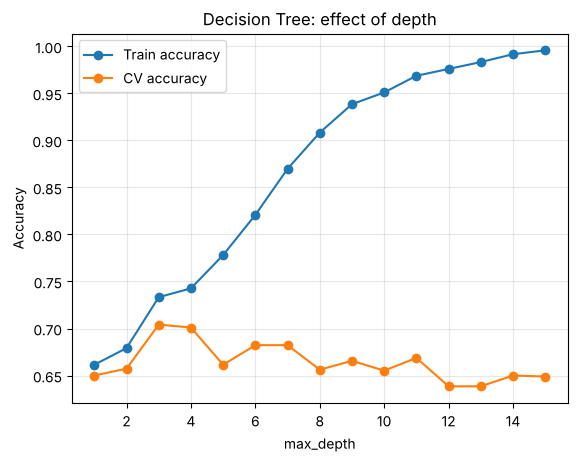

Best max_depth: 3 with CV accuracy 0.704
At max_depth 15: train accuracy 0.996 , CV accuracy 0.649


In [15]:
# a tree does not need scaling, so the unscaled data is used here (the splits are easier to read)
depths = range(1, 16)
train_acc, cv_acc = [], []
for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_acc.append(cross_val_score(tree, X_train, y_train, cv=5).mean())
    train_acc.append(tree.fit(X_train, y_train).score(X_train, y_train))

plt.plot(depths, train_acc, marker="o", label="Train accuracy")
plt.plot(depths, cv_acc, marker="o", label="CV accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: effect of depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_depth = list(depths)[int(np.argmax(cv_acc))]
print("Best max_depth:", best_depth, "with CV accuracy", round(max(cv_acc), 3))
print("At max_depth 15: train accuracy", round(train_acc[-1], 3), ", CV accuracy", round(cv_acc[-1], 3))

In [16]:
tree = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
evaluate("Decision Tree", tree, X_train, X_test)

Accuracy       : 0.7500
Precision      : 0.7647
Recall         : 0.6190
F1-score       : 0.6842
Log Loss       : 0.5489
ROC AUC        : 0.7865
Train Accuracy : 0.7333

              precision    recall  f1-score   support

  Not Placed       0.74      0.85      0.79       135
      Placed       0.76      0.62      0.68       105

    accuracy                           0.75       240
   macro avg       0.75      0.74      0.74       240
weighted avg       0.75      0.75      0.75       240



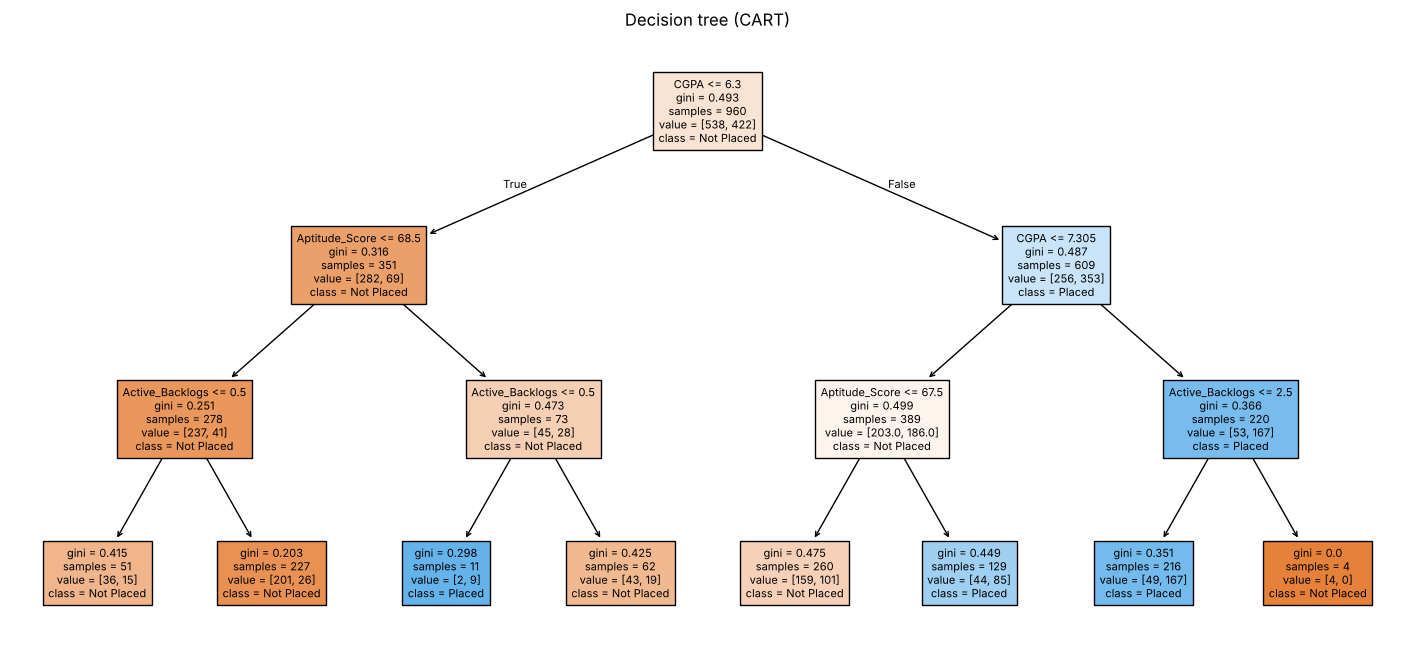

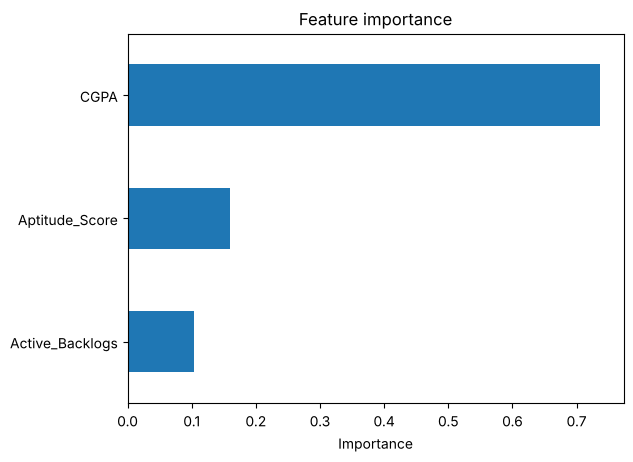

CGPA               0.736
Aptitude_Score     0.160
Active_Backlogs    0.103
dtype: float64


In [17]:
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=list(X_train.columns), class_names=["Not Placed", "Placed"],
          filled=True, max_depth=3, fontsize=8)
plt.title("Decision tree (CART)")
plt.show()

# only the features that the tree actually used
importance = pd.Series(tree.feature_importances_, index=X_train.columns)
importance = importance[importance > 0].sort_values()
importance.plot(kind="barh")
plt.title("Feature importance")
plt.xlabel("Importance")
plt.show()
print(importance.sort_values(ascending=False).round(3))

Training accuracy rises to 0.996 as depth grows, but CV accuracy drops from 0.704 (depth 3) to 0.649 (depth 15), so deep trees overfit. Depth 3 was used. Only CGPA (0.736), Aptitude_Score (0.160) and Active_Backlogs (0.103) are used. It has the highest precision (0.765), the lowest recall (0.619) and the lowest AUC (0.787).

## KNN

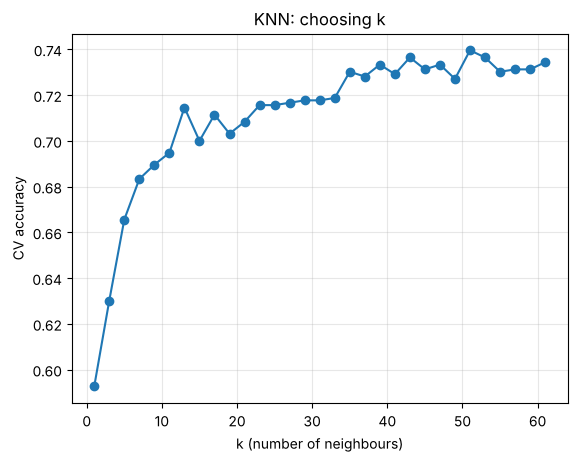

Best k: 51 with CV accuracy 0.74
CV accuracy at k = 1: 0.593


In [18]:
# odd values of k only, so that there are no ties for 2 classes
ks = list(range(1, 62, 2))
knn_cv = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=5).mean() for k in ks]

plt.plot(ks, knn_cv, marker="o")
plt.xlabel("k (number of neighbours)")
plt.ylabel("CV accuracy")
plt.title("KNN: choosing k")
plt.grid(alpha=0.3)
plt.show()

best_k = ks[int(np.argmax(knn_cv))]
print("Best k:", best_k, "with CV accuracy", round(max(knn_cv), 3))
print("CV accuracy at k = 1:", round(knn_cv[0], 3))

In [19]:
knn = KNeighborsClassifier(n_neighbors=best_k)
evaluate("KNN", knn, X_train_s, X_test_s)

Accuracy       : 0.7458
Precision      : 0.7444
Recall         : 0.6381
F1-score       : 0.6872
Log Loss       : 0.5549
ROC AUC        : 0.8099
Train Accuracy : 0.7500

              precision    recall  f1-score   support

  Not Placed       0.75      0.83      0.79       135
      Placed       0.74      0.64      0.69       105

    accuracy                           0.75       240
   macro avg       0.75      0.73      0.74       240
weighted avg       0.75      0.75      0.74       240



CV accuracy is low for small k (0.593 at k = 1) and levels off at 0.73 to 0.74 from k = 35. Best k = 51. It has the highest log loss of the four models (0.5549).

## Naive Bayes

In [20]:
nb_model = GaussianNB()
evaluate("Naive Bayes", nb_model, X_train_s, X_test_s)
print("Class priors (Not Placed, Placed):", nb_model.class_prior_.round(3))

Accuracy       : 0.7583
Precision      : 0.7196
Recall         : 0.7333
F1-score       : 0.7264
Log Loss       : 0.5360
ROC AUC        : 0.8390
Train Accuracy : 0.7583

              precision    recall  f1-score   support

  Not Placed       0.79      0.78      0.78       135
      Placed       0.72      0.73      0.73       105

    accuracy                           0.76       240
   macro avg       0.75      0.76      0.75       240
weighted avg       0.76      0.76      0.76       240

Class priors (Not Placed, Placed): [0.56 0.44]


Highest recall (0.733) and F1 (0.726) but lowest precision (0.720), with 30 false positives. Accuracy (0.7583) is close to the SVM even though the features are correlated, so the independence assumption is not fully true.

# 3. Comparative Analysis

## Results Table

In [21]:
results_df = pd.DataFrame(results).T.round(4)
results_df

,Accuracy,Precision,Recall,F1-score,Log Loss,ROC AUC,Train Accuracy
SVM,0.7625,0.7553,0.6762,0.7136,0.4538,0.8641,0.7906
Decision Tree,0.7500,0.7647,0.6190,0.6842,0.5489,0.7865,0.7333
KNN,0.7458,0.7444,0.6381,0.6872,0.5549,0.8099,0.7500
Naive Bayes,0.7583,0.7196,0.7333,0.7264,0.5360,0.8390,0.7583


In [22]:
for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC AUC"]:
    print(f"Best {metric:10}:", results_df[metric].idxmax(), "-", results_df[metric].max())
print(f"Lowest Log Loss  :", results_df["Log Loss"].idxmin(), "-", results_df["Log Loss"].min())

Best Accuracy  : SVM - 0.7625
Best Precision : Decision Tree - 0.7647
Best Recall    : Naive Bayes - 0.7333
Best F1-score  : Naive Bayes - 0.7264
Best ROC AUC   : SVM - 0.8641
Lowest Log Loss  : SVM - 0.4538


## Metrics Comparison

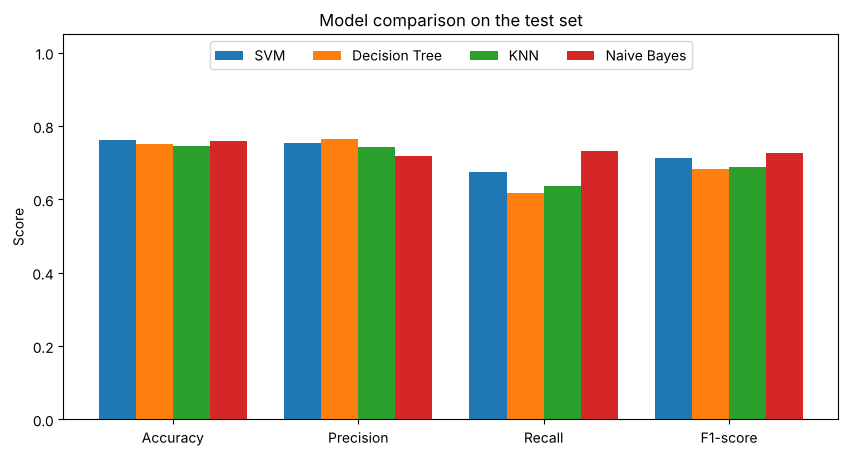

In [23]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
names = list(results_df.index)
x = np.arange(len(metrics))
width = 0.2

plt.figure(figsize=(10, 5))
for i, name in enumerate(names):
    plt.bar(x + i * width, results_df.loc[name, metrics], width, label=name)
plt.xticks(x + 1.5 * width, metrics)
plt.ylim(0, 1.05)
plt.ylabel("Score")
plt.title("Model comparison on the test set")
plt.legend(loc="upper center", ncol=4)
plt.show()

## Confusion Matrices

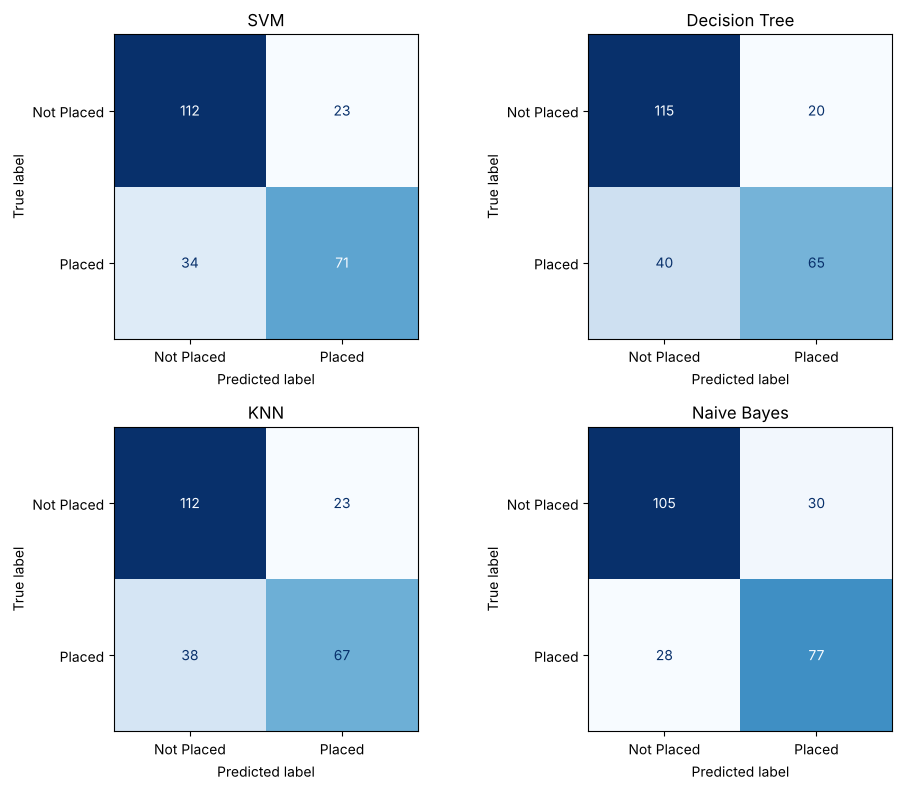

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, name in zip(axes.flatten(), names):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], display_labels=["Not Placed", "Placed"],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## ROC Curves

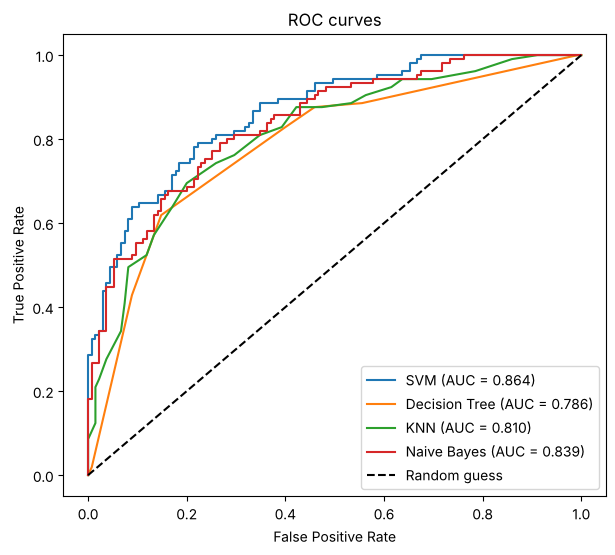

In [25]:
plt.figure(figsize=(7, 6))
for name in names:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results[name]['ROC AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves")
plt.legend()
plt.show()

## Loss and Overfitting

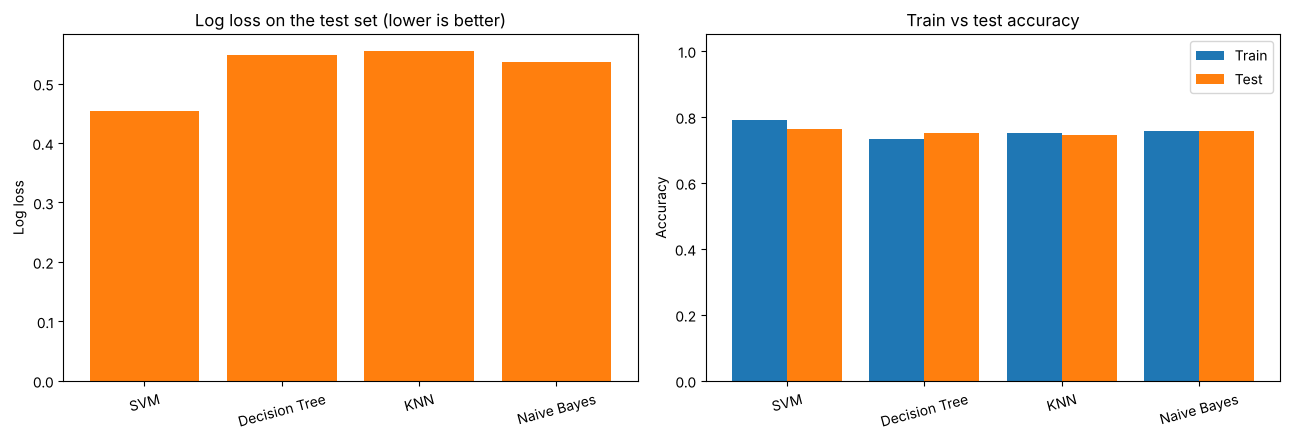

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].bar(names, results_df["Log Loss"], color="tab:orange")
ax[0].set_title("Log loss on the test set (lower is better)")
ax[0].set_ylabel("Log loss")
ax[0].tick_params(axis="x", rotation=15)

x = np.arange(len(names))
ax[1].bar(x - 0.2, results_df["Train Accuracy"], 0.4, label="Train")
ax[1].bar(x + 0.2, results_df["Accuracy"], 0.4, label="Test")
ax[1].set_xticks(x)
ax[1].set_xticklabels(names, rotation=15)
ax[1].set_ylim(0, 1.05)
ax[1].set_title("Train vs test accuracy")
ax[1].set_ylabel("Accuracy")
ax[1].legend()

plt.tight_layout()
plt.show()

## Cross Validation Check

In [27]:
# the test set has only 240 students, so 5-fold CV on the training set is checked as well
# (shuffled folds, different from the ones used for choosing k, depth, kernel and C)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
cv_rows = []
for name in names:
    scores = cross_val_score(models[name], inputs[name], y_train, cv=folds)
    cv_rows.append([name, round(scores.mean(), 4), round(scores.std(), 4)])

pd.DataFrame(cv_rows, columns=["Model", "CV mean accuracy", "CV std"])

,Model,CV mean accuracy,CV std
0,SVM,0.7750,0.0196
1,Decision Tree,0.7052,0.0210
2,KNN,0.7240,0.0226
3,Naive Bayes,0.7396,0.0165


Loss is log loss from the predicted probabilities (lower is better).

* All accuracies are between 0.746 and 0.763, a gap of about 4 students out of 240, so accuracy alone does not separate the models.
* SVM is best on accuracy, ROC AUC (0.864) and log loss (0.4538).
* Naive Bayes is best on recall and F1. Decision Tree is best on precision.
* 5-fold CV on new folds: SVM 0.775, Naive Bayes 0.740, KNN 0.724, Decision Tree 0.705. SVM, KNN and the tree were tuned with CV, so their scores are slightly optimistic.
* No model overfits much: train accuracy 0.73 to 0.79, test accuracy 0.75 to 0.76.

# 4. Conclusion

SVM (linear kernel) gave the best overall result (accuracy 0.7625, AUC 0.864, log loss 0.4538, CV accuracy 0.775). Naive Bayes was best at finding placed students (recall 0.733, F1 0.726). Decision Tree and KNN were weaker. The differences on the test set are small. CGPA, aptitude score and active backlogs are the main factors for placement.

* **SVM:** good for small or medium data with many numeric features. Needs scaling, slow on very large data, hard to interpret.
* **Decision Tree:** easy to explain and needs no scaling, but overfits unless the depth is limited.
* **KNN:** simple with no training step, but needs scaling, is slow on large data and is affected by useless features.
* **Naive Bayes:** very fast and works with little data, good for text classification. Assumes features are independent.

**Ethics and limits:** the model uses gender, city tier and family income, which are not things a student controls, so using it to shortlist or reject students could be unfair. It should only support a placement cell, not decide for it. Only 1,200 students from one dataset were used, so the results may not carry over to another college. Future work: check the model for bias between groups, try ensembles such as random forests, and tune with a larger search.